# Análisis exploratorio y modelo de riesgo académico
**Chatbot de Apoyo Académico · Ingeniería de Sistemas UNAB**

Este cuaderno cumple dos objetivos:
1. **EDA** de la base sintética que simula Banner/COSMOS (notas, reprobación, deserción, competencias digitales).
2. Entrenar un **modelo de riesgo** que estima la probabilidad de que un estudiante quede *en prueba académica*
   (PGA < 3.0, o entre 3.0 y 3.2 dos periodos seguidos — Reglamento UNAB 2019, art. 24) en el siguiente periodo.
   El modelo se exporta a `mcp_server/modelo_riesgo.json` y lo usa la herramienta MCP
   `recomendaciones_personalizadas` para personalizar las respuestas del chatbot.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid", palette="viridis")
D = Path("../data/synthetic")
est = pd.read_csv(D/"estudiante.csv"); ins = pd.read_csv(D/"inscripcion.csv"); cur = pd.read_csv(D/"curso.csv")
mat = pd.read_csv(D/"matricula.csv"); cd = pd.read_csv(D/"cd_inscripcion.csv"); per = pd.read_csv(D/"periodo.csv")
ins = ins.merge(cur[["curso_id","nombre","creditos","semestre_sugerido","dificultad"]], on="curso_id")
print(f"{len(est)} estudiantes · {len(ins)} inscripciones · {cur.creditos.sum()} créditos en el plan")

420 estudiantes · 9218 inscripciones · 154 créditos en el plan


## 1. Calidad de datos

In [2]:
pd.DataFrame({"nulos": est.isna().sum(), "tipo": est.dtypes}).query("nulos>0")

,nulos,tipo
beca,338,str


In [3]:
ev = ins[ins.nota_final.notna()]
print("Notas fuera de rango:", ((ev.nota_final<0)|(ev.nota_final>5)).sum())
print("Inscripciones duplicadas (codigo, curso, periodo):", ins.duplicated(["codigo","curso_id","periodo_id"]).sum())
ev.nota_final.describe().round(2)

Notas fuera de rango: 0
Inscripciones duplicadas (codigo, curso, periodo): 0


count    7522.00
mean        3.55
std         0.71
min         0.90
25%         3.10
50%         3.60
75%         4.00
max         5.00
Name: nota_final, dtype: float64

## 2. Distribución de notas y reprobación

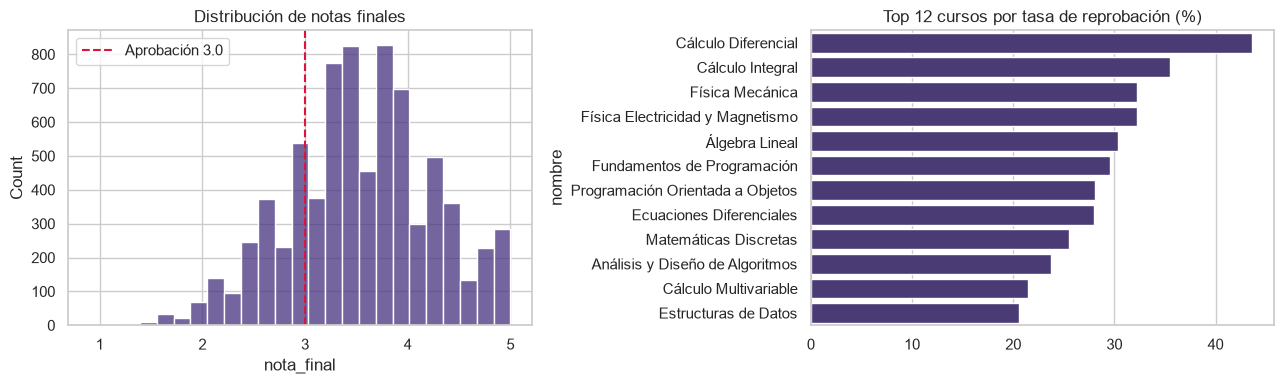

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(ev.nota_final, bins=25, ax=ax[0]); ax[0].axvline(3.0, color="crimson", ls="--", label="Aprobación 3.0"); ax[0].legend()
ax[0].set_title("Distribución de notas finales")
rep = ev.assign(rep=ev.estado.eq("Reprobado")).groupby("nombre").rep.mean().sort_values(ascending=False).head(12)*100
sns.barplot(x=rep.values, y=rep.index, ax=ax[1]); ax[1].set_title("Top 12 cursos por tasa de reprobación (%)")
plt.tight_layout(); plt.show()

In [5]:
por_sem = ev.assign(rep=ev.estado.eq("Reprobado")).groupby("semestre_sugerido").agg(nota=("nota_final","mean"), reprobacion=("rep","mean"))
por_sem.assign(reprobacion=lambda d: (d.reprobacion*100).round(1)).round(2)

,nota,reprobacion
semestre_sugerido,,
1,3.49,22.6
2,3.46,23.9
3,3.47,21.5
4,3.61,13.5
5,3.78,8.8
6,3.73,12.4
7,3.86,8.5
8,3.95,6.2
9,4.60,0.0


Los cursos de **matemáticas y física de los primeros semestres** concentran la reprobación: son los cuellos de botella que el chatbot prioriza en sus alertas.

## 3. Deserción y condición académica

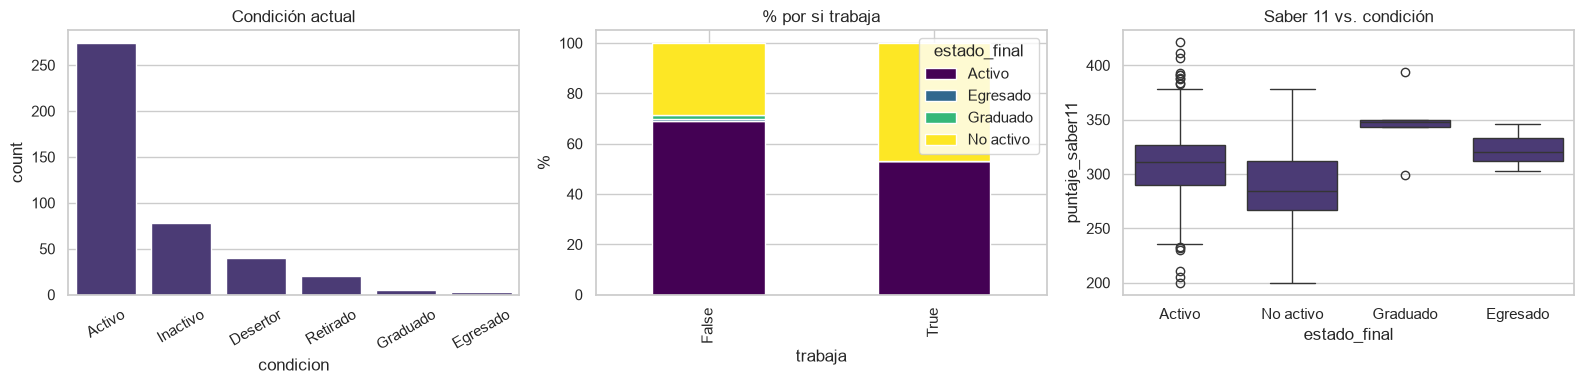

In [6]:
est["estado_final"] = est.condicion.replace({"Desertor":"No activo","Retirado":"No activo","Inactivo":"No activo"})
fig, ax = plt.subplots(1, 3, figsize=(16,4))
sns.countplot(data=est, x="condicion", ax=ax[0], order=est.condicion.value_counts().index); ax[0].tick_params(axis="x", rotation=30)
ax[0].set_title("Condición actual")
pd.crosstab(est.trabaja, est.estado_final, normalize="index").mul(100).plot.bar(stacked=True, ax=ax[1], colormap="viridis")
ax[1].set_title("% por si trabaja"); ax[1].set_ylabel("%")
sns.boxplot(data=est, x="estado_final", y="puntaje_saber11", ax=ax[2]); ax[2].set_title("Saber 11 vs. condición")
plt.tight_layout(); plt.show()

## 4. Competencias digitales (CCD)

In [7]:
ok = cd[cd.estado.isin(["Aprobado","Validado por prueba"])]
print("Estudiantes con al menos un curso CD aprobado:", ok.codigo.nunique())
ok.merge(pd.read_csv(D/"cd_curso.csv")[["cd_curso_id","nombre","ruta"]], on="cd_curso_id").groupby(["ruta","nombre"]).size().rename("aprobados").to_frame()

Estudiantes con al menos un curso CD aprobado: 363


aprobados
ruta nombre                                     
0    Cultura Digital y Vida en Línea         195
     Excel                                   162
     PowerPoint                               93
     Word                                    124
1    Interacción Digital                      92
2    Creación de Contenidos Digitales         19
     Habilidades de Analítica Digital         19
     Marca Personal Digital                   18
3    Cuidado y Bienestar Digital              13
     IA Generativa                            67
     Marco Legal Digital                      12

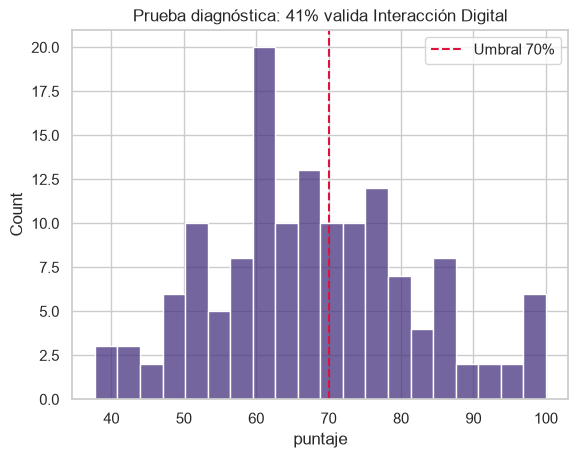

In [8]:
pr = pd.read_csv(D/"cd_prueba_diagnostica.csv")
ax = sns.histplot(pr.puntaje, bins=20); ax.axvline(70, color="crimson", ls="--", label="Umbral 70%"); ax.legend()
ax.set_title(f"Prueba diagnóstica: {(pr.puntaje>=70).mean():.0%} valida Interacción Digital"); plt.show()

## 5. Dataset para el modelo de riesgo
Unidad de análisis: **estudiante-periodo**. Con la información disponible al cierre del periodo *t* se predice
si en *t+1* quedará en prueba académica.

In [9]:
per["orden"] = per.anio*2 + per.numero
ev = ev.merge(per[["periodo_id","orden"]], on="periodo_id")
g = ev.groupby(["codigo","orden"]).apply(lambda d: pd.Series({
        "pga_periodo": np.average(d.nota_final, weights=d.creditos),
        "cred_eval": d.creditos.sum(),
        "cred_aprob": d.loc[d.estado=="Aprobado","creditos"].sum(),
        "reprobados": (d.estado=="Reprobado").sum()}), include_groups=False).reset_index().sort_values(["codigo","orden"])
g["puntos"] = g.pga_periodo*g.cred_eval
g["pga_acumulado"] = g.groupby("codigo").puntos.cumsum()/g.groupby("codigo").cred_eval.cumsum()
g["n"] = g.groupby("codigo").cumcount()+1
g["reprobados_por_periodo"] = g.groupby("codigo").reprobados.cumsum()/g.n
g["creditos_por_periodo"] = g.groupby("codigo").cred_aprob.cumsum()/g.n
g["pga_ultimo_periodo"] = g.pga_periodo
banda = np.select([g.pga_periodo>3.2, g.pga_periodo>=3.0], ["N","C"], "P")
prev = pd.Series(banda).groupby(g.codigo.values).shift()
g["prueba"] = ((banda=="P") | ((banda=="C") & prev.isin(["C","P"]).values)).astype(int)
g["y"] = g.groupby("codigo").prueba.shift(-1)
g = g.merge(est[["codigo","trabaja","puntaje_saber11"]], on="codigo")
g["trabaja"] = g.trabaja.astype(float)
data = g.dropna(subset=["y"])
FEATS = ["pga_acumulado","pga_ultimo_periodo","reprobados_por_periodo","creditos_por_periodo","trabaja"]
print(data.shape, "· tasa positiva:", round(data.y.mean(),3))
data[FEATS+["y"]].describe().round(2)

(1020, 16) · tasa positiva: 0.18


,pga_acumulado,pga_ultimo_periodo,reprobados_por_periodo,creditos_por_periodo,trabaja,y
count,1020.00,1020.00,1020.00,1020.00,1020.00,1020.00
mean,3.50,3.50,1.03,12.90,0.18,0.18
std,0.41,0.45,0.99,3.53,0.38,0.38
min,2.21,2.21,0.00,0.00,0.00,0.00
25%,3.22,3.21,0.25,10.70,0.00,0.00
50%,3.49,3.50,1.00,13.33,0.00,0.00
75%,3.76,3.81,1.50,15.67,0.00,0.00
max,4.65,5.00,7.00,20.00,1.00,1.00


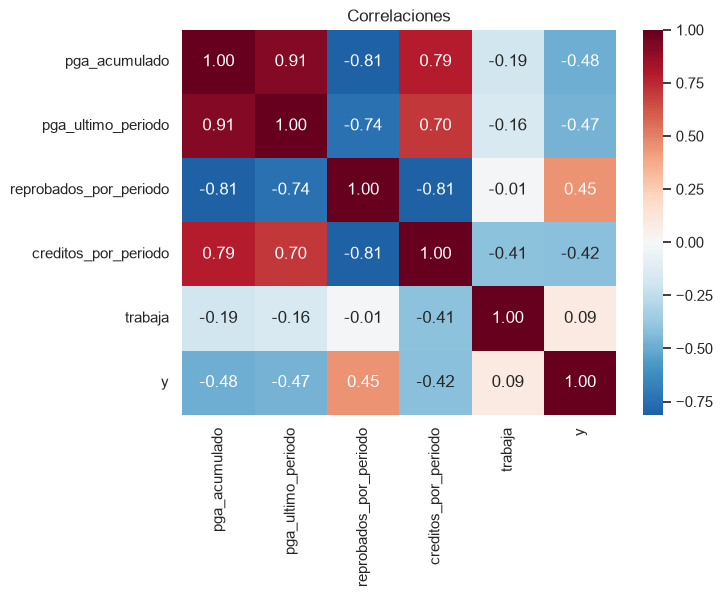

In [10]:
plt.figure(figsize=(7,5)); sns.heatmap(data[FEATS+["y"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlaciones"); plt.show()

## 6. Entrenamiento y evaluación (partición por estudiante para evitar fuga de información)

In [11]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, RocCurveDisplay, brier_score_loss
from sklearn.pipeline import make_pipeline
X, y, grp = data[FEATS].values, data.y.astype(int).values, data.codigo.values
tr, te = next(GroupShuffleSplit(test_size=0.25, random_state=42).split(X, y, grp))
logit = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X[tr], y[tr])
rf = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42).fit(X[tr], y[tr])
res = {}
for nombre, m in [("Regresión logística", logit), ("Random Forest", rf)]:
    p = m.predict_proba(X[te])[:,1]
    res[nombre] = {"AUC": roc_auc_score(y[te], p), "Brier": brier_score_loss(y[te], p)}
pd.DataFrame(res).T.round(3)

,AUC,Brier
Regresión logística,0.854,0.148
Random Forest,0.851,0.136


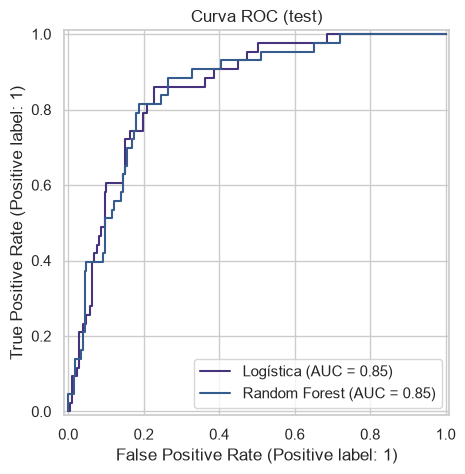

                  precision    recall  f1-score   support

      Sin riesgo       0.95      0.80      0.87       207
Prueba académica       0.45      0.79      0.58        43

        accuracy                           0.80       250
       macro avg       0.70      0.80      0.72       250
    weighted avg       0.86      0.80      0.82       250



In [12]:
fig, ax = plt.subplots(figsize=(6,5))
RocCurveDisplay.from_estimator(logit, X[te], y[te], ax=ax, name="Logística")
RocCurveDisplay.from_estimator(rf, X[te], y[te], ax=ax, name="Random Forest"); ax.set_title("Curva ROC (test)"); plt.show()
print(classification_report(y[te], logit.predict(X[te]), target_names=["Sin riesgo","Prueba académica"]))

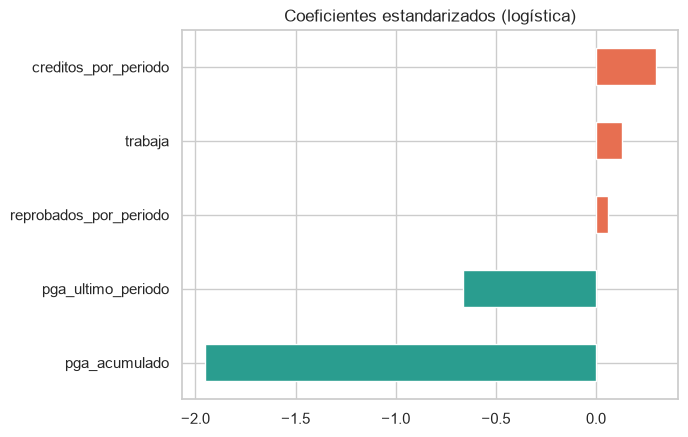

pga_acumulado            -1.953
pga_ultimo_periodo       -0.662
reprobados_por_periodo    0.062
trabaja                   0.129
creditos_por_periodo      0.298
dtype: float64

In [13]:
coef = pd.Series(logit[-1].coef_[0], index=FEATS).sort_values()
coef.plot.barh(color=["#2a9d8f" if c<0 else "#e76f51" for c in coef]); plt.title("Coeficientes estandarizados (logística)"); plt.show()
coef.round(3)

Se elige la **regresión logística**: rendimiento comparable al Random Forest, mejor calibración y es
**interpretable** (el chatbot puede explicar por qué un estudiante está en riesgo).
Un PGA alto reduce el riesgo; reprobar más cursos por periodo y trabajar lo aumentan.

## 7. Exportar el modelo para el servidor MCP

In [14]:
sc, lr = logit[0], logit[-1]
modelo = {"descripcion": "Regresión logística (sklearn) · P(prueba académica en t+1)",
          "features": FEATS, "intercepto": float(lr.intercept_[0]),
          "coeficientes": dict(zip(FEATS, map(float, lr.coef_[0]))),
          "medias": dict(zip(FEATS, map(float, sc.mean_))), "desviaciones": dict(zip(FEATS, map(float, sc.scale_))),
          "metricas_test": {k: round(v, 3) for k, v in res["Regresión logística"].items()},
          "n_entrenamiento": int(len(tr))}
Path("../mcp_server/modelo_riesgo.json").write_text(json.dumps(modelo, indent=2, ensure_ascii=False), encoding="utf-8")
modelo["metricas_test"]

{'AUC': 0.854, 'Brier': 0.148}